#  Optimale Beladung von LKW 

Die Situation ist die folgende: Wir haben eine Spedition mit mehreren LKW und erhalten eine Menge von Aufträgen. Diese gilt es mit den vorhandenen LKW abzuwickeln so dass dies innerhalb vorgegebener Fristen erfüllt werden. Für jeden Auftrag ist ein Preis (bzw. eine Prämie) festgelegt. Die LKW haben unterschiedliche Kapazität. Die Ladung ist - der Einfachheit halber - in normierten Kisten unter gebracht. Diese sind jedoch je nach Inhalt (also je nach Auftrag) unterschiedlich schwer.

Benötigte Bibliotheken: numpy pandas matplotlib seaborn deap ortools

In [32]:
import random
import numpy as np
import pandas as pd
from copy import deepcopy
import matplotlib.pyplot as plt
from collections import defaultdict
from dataclasses import dataclass
from typing import Dict, List, Tuple
from matplotlib import patches
from ortools.sat.python import cp_model

## Einlesen/Festlegen der Auftrags- und LKW-Daten

Einlesen der LKW Informationen. Dazu gehört die maximale Anzahl Kisten, dies ist durch deren einheitliche Größe bestimmbar. Zudem ist die Zuladung durch das Maximalgewicht limitiert. Als Vereinfachung wird die mögliche durchschnittliche Reisegeschwindigkeit des LKW angegeben.

In [35]:
df_trucks = pd.read_csv('./data/CSP_LKW.csv', delimiter=';')
df_trucks.columns = ['truck','maxbox','maxweight','speed']
df_trucks.head()

,truck,maxbox,maxweight,speed
0,1,12,3000,120
1,2,24,5000,100
2,3,24,5000,100
3,4,80,20000,70
4,5,50,10000,80


Die Spalten sind etwas "sperrig" benannt, daher nutzen wir einfachere Namen als in der Originaldatei.

Nun werden die Aufträge eingelesen.

In [38]:
df_orders = pd.read_csv('./data/CSP_Auftraege.csv', delimiter=';')
df_orders.columns = ['order', 'destination', 'distance', 'boxes', 'box_weight', 'payment', 'deadline', 'penalty']
df_orders.head()

,order,destination,distance,boxes,box_weight,payment,deadline,penalty
0,1,A,900,12,150,2450,24,750
1,2,E,750,23,125,1500,24,550
2,3,B,650,24,250,7500,24,3500
3,4,D,1200,48,100,2500,24,1000
4,5,B,650,24,200,6000,24,3000


Was erhält man, wenn alles pünktlich abgeliefert wird?

In [41]:
max_payment = df_orders['payment'].sum()
max_payment

37150

## Schedule - Zuordnung und Auslieferungsplan für die Aufträge

Jedem LKW wird nun eine Reihe von Aufträgen zugeordnet. Der LKW fährt zum Zielort, liefert die Ware ab, kehrt zurück und kann dann neue Ware aufnehmen. Das Be-/Entladen dauert immer eine Stunde.

In [45]:
# Format :  ([lkw_nr, Auftrags_nr], ...)

order_list = []

order_list.append([1,1])
order_list.append([2,2])
order_list.append([3,3])
order_list.append([4,4])
order_list.append([5,5])

order_list

[[1, 1], [2, 2], [3, 3], [4, 4], [5, 5]]

In [59]:
# Funktionen zur Informationsbeschaffung
def get_speed_by_truck_number(df, x):
    try:
        return df.loc[df['truck'] == x, 'speed'].values[0]
    except IndexError:
        return None

def get_distance_by_order_number(df, x):
    try:
        return df.loc[df['order'] == x, 'distance'].values[0]
    except IndexError:
        return None

def get_destination_by_order_number(df, x):
    try:
        return df.loc[df['order'] == x, 'destination'].values[0]
    except IndexError:
        return None

def get_boxes_by_order_number(df, x):
    try:
        return df.loc[df['order'] == x, 'boxes'].values[0]
    except IndexError:
        return None

def get_max_boxes_by_truck_number(df, x):
    try:
        return df.loc[df['truck'] == x, 'maxbox'].values[0]
    except IndexError:
        return None

# Visualisierung der Auslieferung. Rot angezeigt werden Verletzungen der Knotenkonsistenz

def plot_truck_schedule(order_list, df_trucks, df_orders, pause_time=1):
    # Zeitmanagement und Plot-Einstellungen
    trucktime = [0] * (len(df_trucks) + 1)  # +1 um sicherzustellen, dass Index korrekt ist

    row_height = 2
    fig, ax = plt.subplots(figsize=[30, 10])
    ax.set_facecolor('lightgrey')  # Hintergrundfarbe setzen

    for truck_id, order_id in order_list:
        start_time = trucktime[truck_id]
        distance = get_distance_by_order_number(df_orders, order_id)
        speed = get_speed_by_truck_number(df_trucks, truck_id)
        if speed == 0:
            continue
        
        # Berechnung der Zeiten
        travel_time = distance / speed
        arrival_time = start_time + travel_time
        back_time = arrival_time + pause_time + travel_time
        trucktime[truck_id] = back_time + pause_time  # zusätzliche Pause vor erneuter Fahrt
        
        # Bestimme die Farbe des Balkens basierend auf der Box-Kapazität
        num_boxes = get_boxes_by_order_number(df_orders, order_id)
        max_boxes = get_max_boxes_by_truck_number(df_trucks, truck_id)
        color = 'lightblue' if num_boxes <= max_boxes else 'red'  # Verschiedene Farben bei Überladung

        # Fahren hellblau einzeichnen
        ax.add_patch(patches.Rectangle(
            (start_time, truck_id * row_height - 1), travel_time, 1.2, edgecolor='black', facecolor=color, lw=1
        ))
        
        # Rückfahrt mit Schraffierung
        ax.add_patch(patches.Rectangle(
            (arrival_time + pause_time, truck_id * row_height - 1), travel_time, 1.2, edgecolor='black', facecolor=color, lw=1, hatch='//', alpha=0.5
        ))

        # Annotate the trip with the destination, order, boxes, and capacity
        ax.text(
            start_time + 0.05, truck_id * row_height + 0.5,
            f"Order {order_id}: T{truck_id} to {get_destination_by_order_number(df_orders, order_id)} | Boxes: {num_boxes} ({max_boxes})",
            ha="left", va="center", fontsize=14  # Größere Schriftgröße
        )

    # Diagramm-Einstellungen
    ax.set_xlabel("Time (hours)", fontsize=16)
    ax.set_title("Truck Delivery Schedule with Order Details", fontsize=18)
    ax.set_xlim(0, max(trucktime) + 2)
    ax.set_ylim(-1, max(truck_id for truck_id, _ in order_list) * row_height + 1)
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    ax.get_yaxis().set_visible(False)  # Y-Achsen-Beschriftungen verstecken

    # Add margins and display the plot
    plt.margins(0.05)
    plt.tight_layout()
    plt.show()

Wir können zufällig eine Verteilung der Aufträge auf die LKW generieren.

In [51]:
import random

def generate_order_list(num_trucks, num_orders):
    order_list = []

    # Eine Liste der Aufträge erstellen
    orders = list(range(1, num_orders + 1))
    
    # Die Reihenfolge der Aufträge zufällig mischen
    random.shuffle(orders)

    # Jedem Auftrag einen zufälligen Truck zuordnen
    for order_id in orders:
        # Weisen Sie jedem Auftrag zufällig eine LKW-Nummer zu
        truck_id = random.randint(1, num_trucks)
        order_list.append([truck_id, order_id])

    return order_list


# Beispiel: 
Zuweisung von Aufträgen zu LKW und Darstellung der Abläufe.

In [67]:
num_trucks = len(df_trucks)-1  # Anzahl der verfügbaren Trucks
num_orders = len(df_orders)-1  # Anzahl der Aufträge
random_order_list = generate_order_list(num_trucks, num_orders)
print(random_order_list)

[[5, 1], [1, 2], [1, 5], [4, 8], [4, 3], [2, 4], [5, 10], [1, 9], [5, 7], [1, 6]]


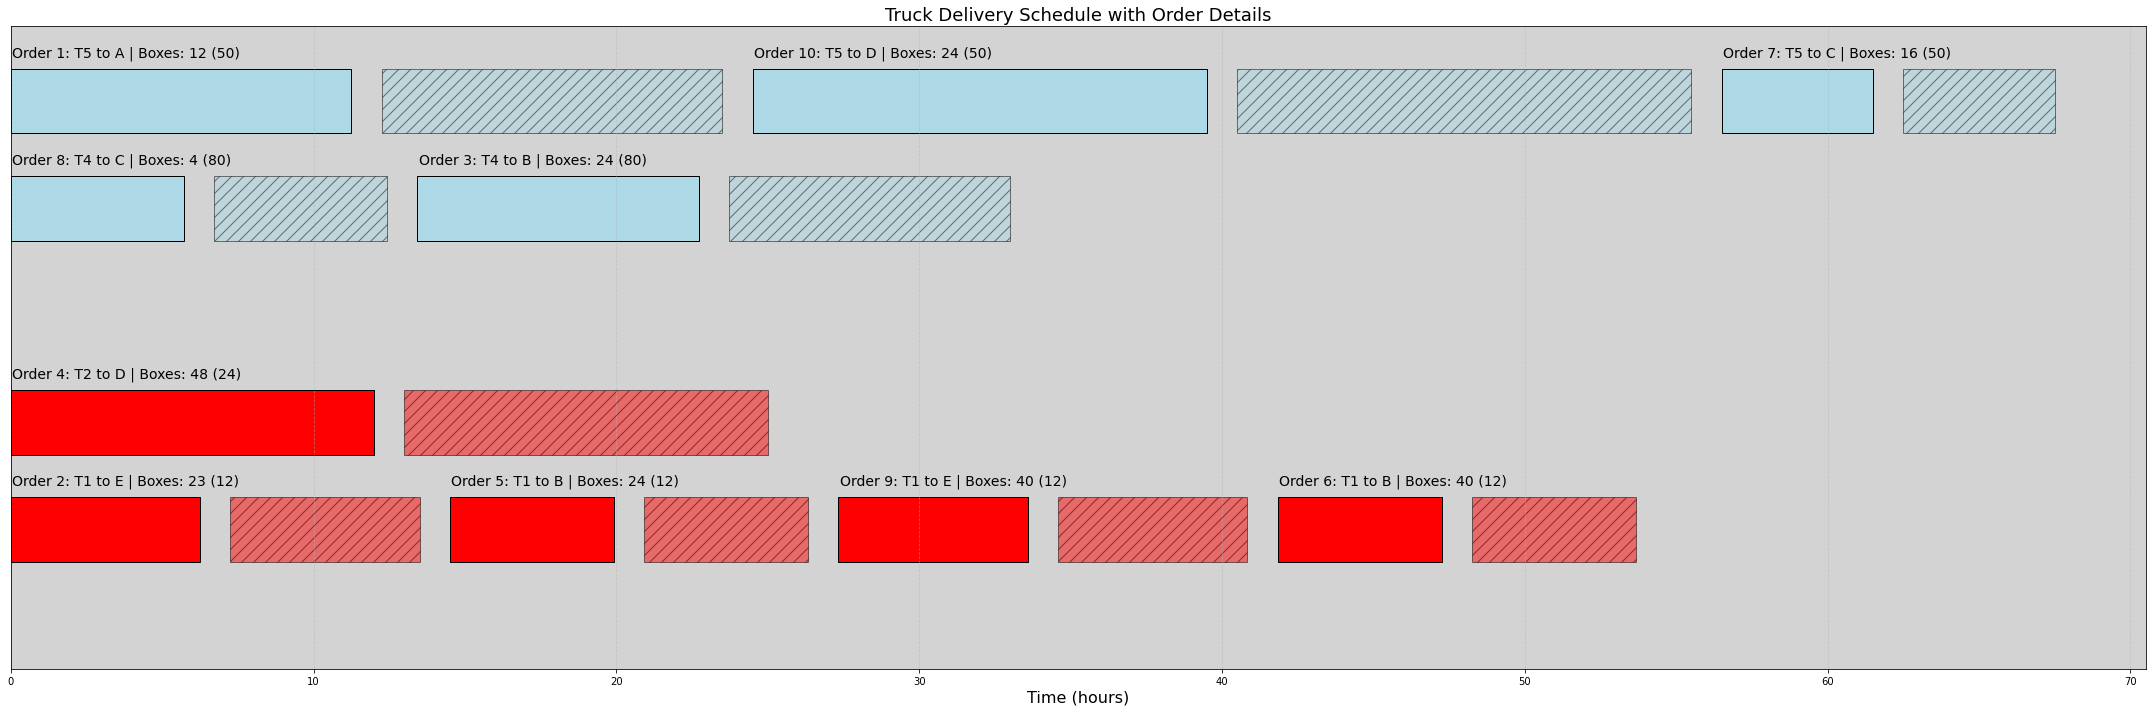

In [69]:
plot_truck_schedule(random_order_list, df_trucks, df_orders, pause_time=1)

# Aufgabe

1) Spielen Sie mit dem System - erstellen Sie manuell eine Zuteilung, welche knotenkonsistent ist.<br>
2) Erstellen Sie ein CSP - definieren Sie Variablen, Wertebereiche und Constraints.<br>
3) Setzen Sie dies mit einer Python Bibliothek um.<br>

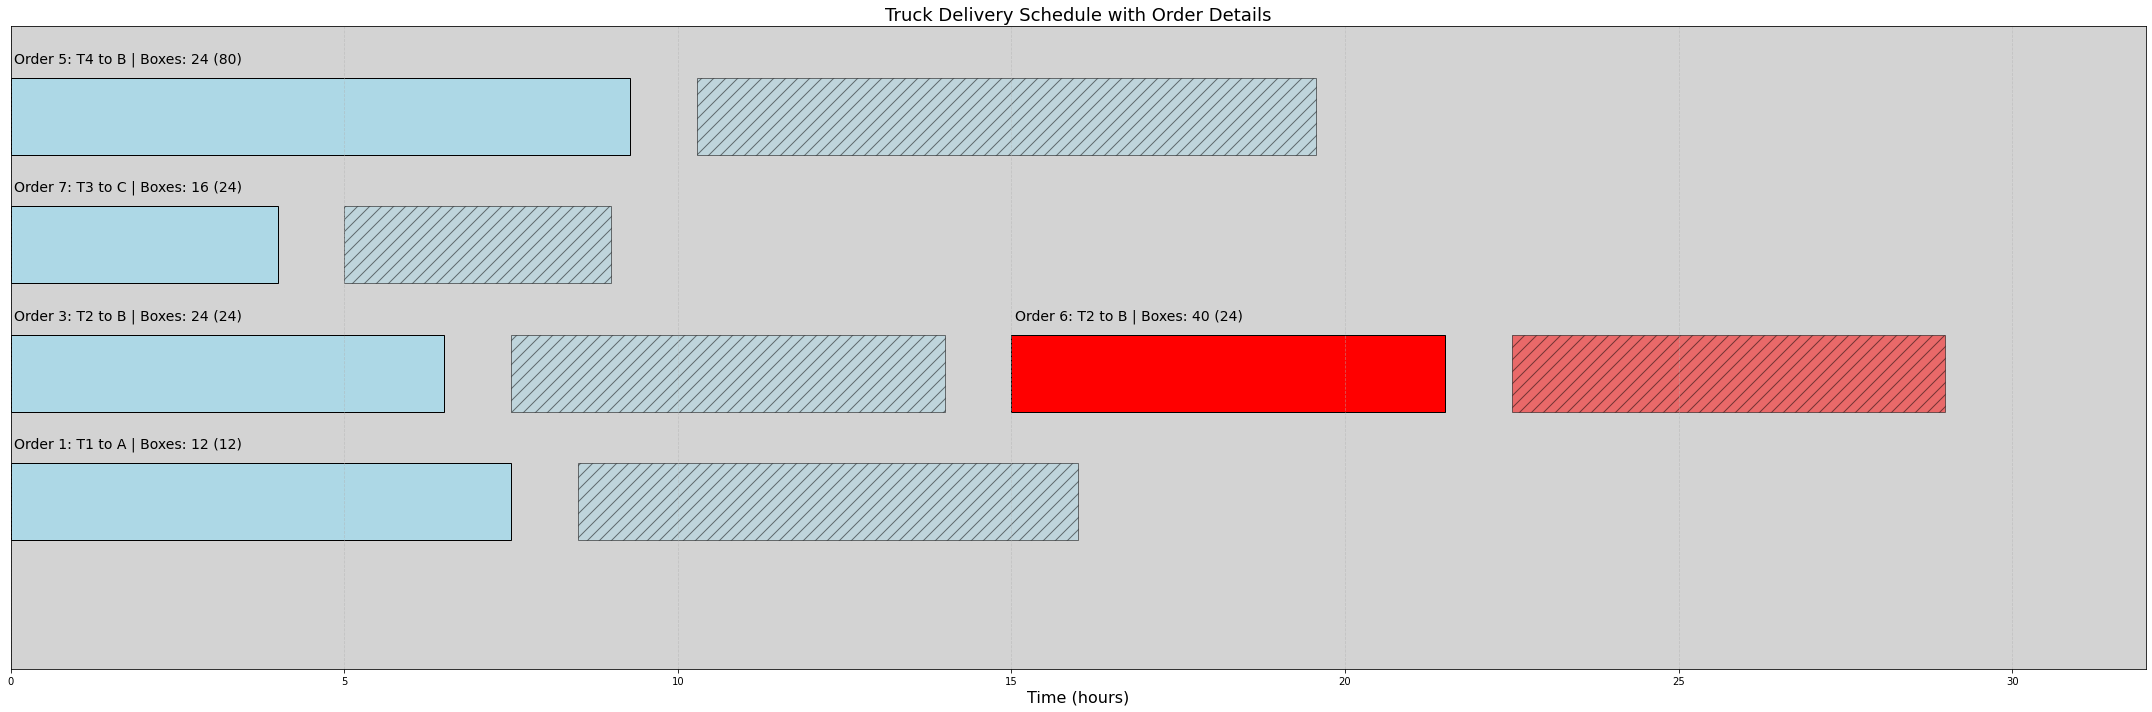

In [76]:
# tragen Sie hier Ihre Auftragszuteilung ein

my_order_list = [[1,1],[2,3],[4,5],[3,7],[2,6]]

plot_truck_schedule(my_order_list, df_trucks, df_orders, pause_time=1)